# Heart Disease Prediction – Complete ML Project
Sab tasks (1–7) + best model ko pickle mein save karna.

## Task 1: Data Loading and Initial Exploration

Shape: (1025, 14)
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Null values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


target
1    526
0    499
Name: count, dtype: int64


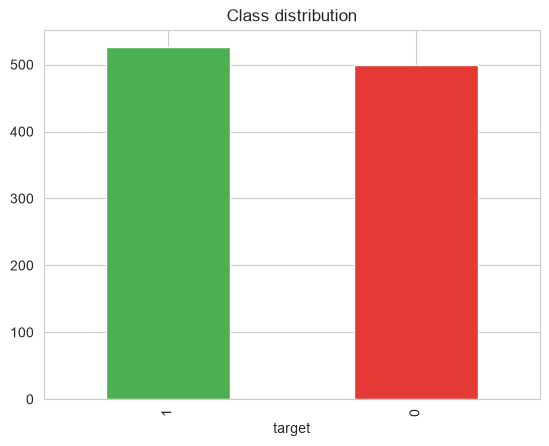

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
sns.set_style('whitegrid')
df = pd.read_csv('heart.csv')
print('Shape:', df.shape)
df.info()
print('\nNull values:\n', df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
display(df.describe().T)
print(df['target'].value_counts())
df['target'].value_counts().plot(kind='bar', color=['#4CAF50','#E53935']); plt.title('Class distribution'); plt.show()

**Note:** Notebook mein dataset ki description (918 rows, text columns jaise `ChestPainType`) is `heart.csv` se match nahi karti. Asli file mein 1025 rows aur 14 numeric-coded columns hain (UCI Cleveland dataset: `cp, thalach, ca, thal...`). Hum asli file ke hisaab se kaam kar rahe hain.

**Important:** 1025 mein se **723 rows duplicate** hain. Agar duplicates train aur test dono mein chale jaye to model test data ko pehle hi dekh chuka hota hai (data leakage) aur accuracy jhooti (~100%) aati hai. Isliye hum duplicates hata dete hain (302 unique rows).

## Task 2: Data Preprocessing

In [2]:
df = df.drop_duplicates().reset_index(drop=True)
print('After removing duplicates:', df.shape)
print('Missing values:', df.isnull().sum().sum())

numeric_cols     = ['age','trestbps','chol','thalach','oldpeak']
categorical_cols = ['sex','cp','fbs','restecg','exang','slope','ca','thal']   # coded categories -> one-hot

X = df.drop('target', axis=1)
y = df['target']
print('Class balance:\n', y.value_counts(normalize=True).round(3))   # ~54/46 -> balanced, SMOTE ki zaroorat nahi

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
preprocess = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)])

After removing duplicates: (302, 14)
Missing values: 0
Class balance:
 target
1    0.543
0    0.457
Name: proportion, dtype: float64


Scaling aur encoding ko ek `Pipeline` ke andar rakha hai taake test data par leakage na ho aur pickle mein preprocessing bhi save ho jaye.

## Task 3: Exploratory Data Analysis

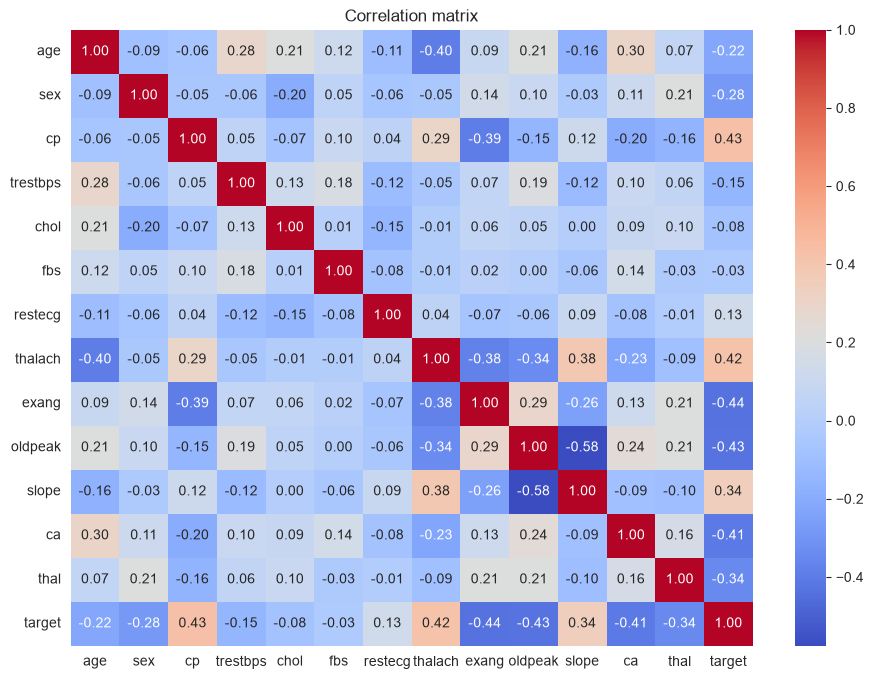

In [3]:
plt.figure(figsize=(11,8)); sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.title('Correlation matrix'); plt.show()

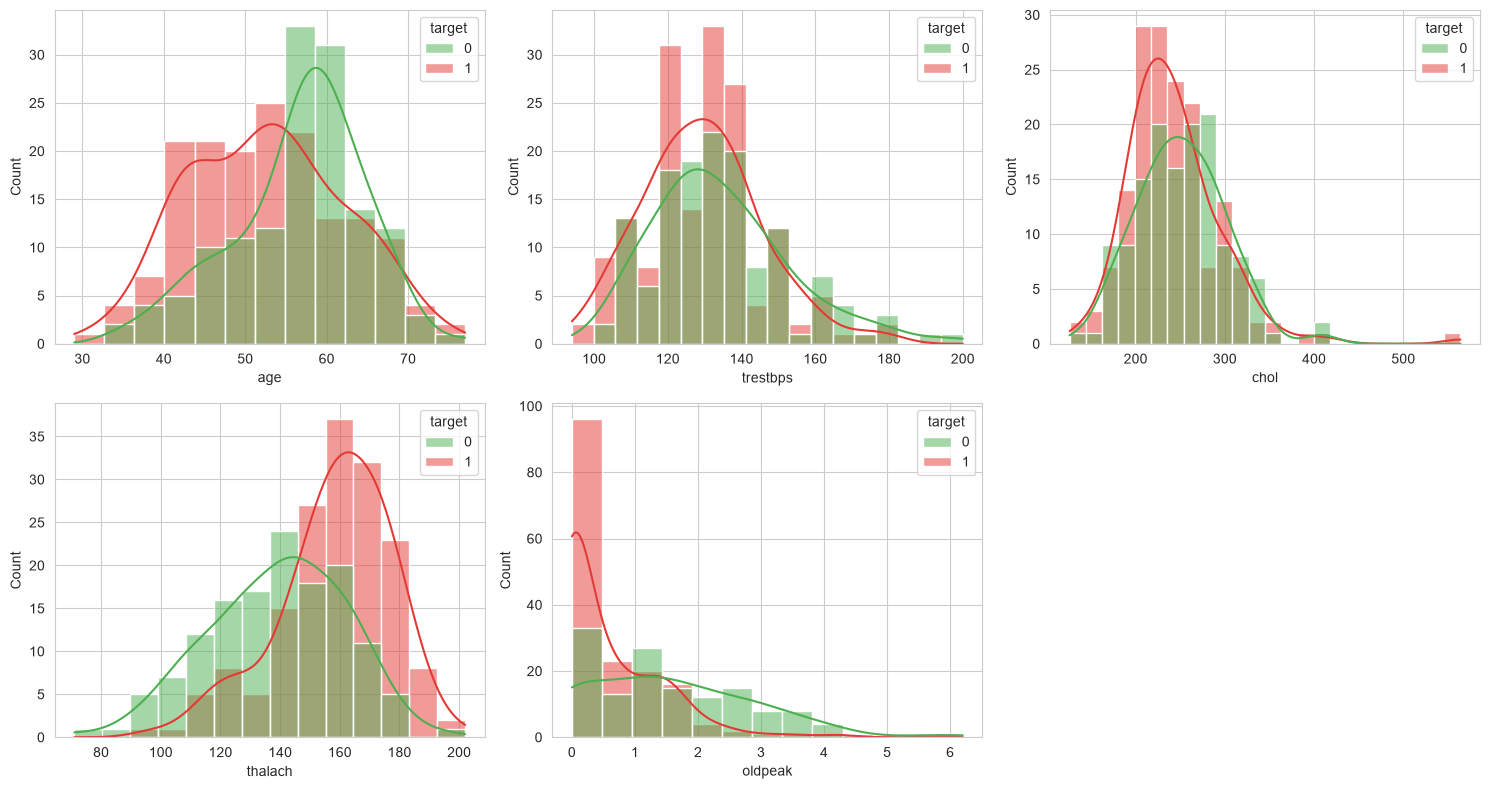

In [4]:
fig, ax = plt.subplots(2,3, figsize=(15,8))
for a, c in zip(ax.ravel(), numeric_cols):
    sns.histplot(data=df, x=c, hue='target', kde=True, ax=a, palette=['#4CAF50','#E53935'])
ax.ravel()[-1].axis('off'); plt.tight_layout(); plt.show()

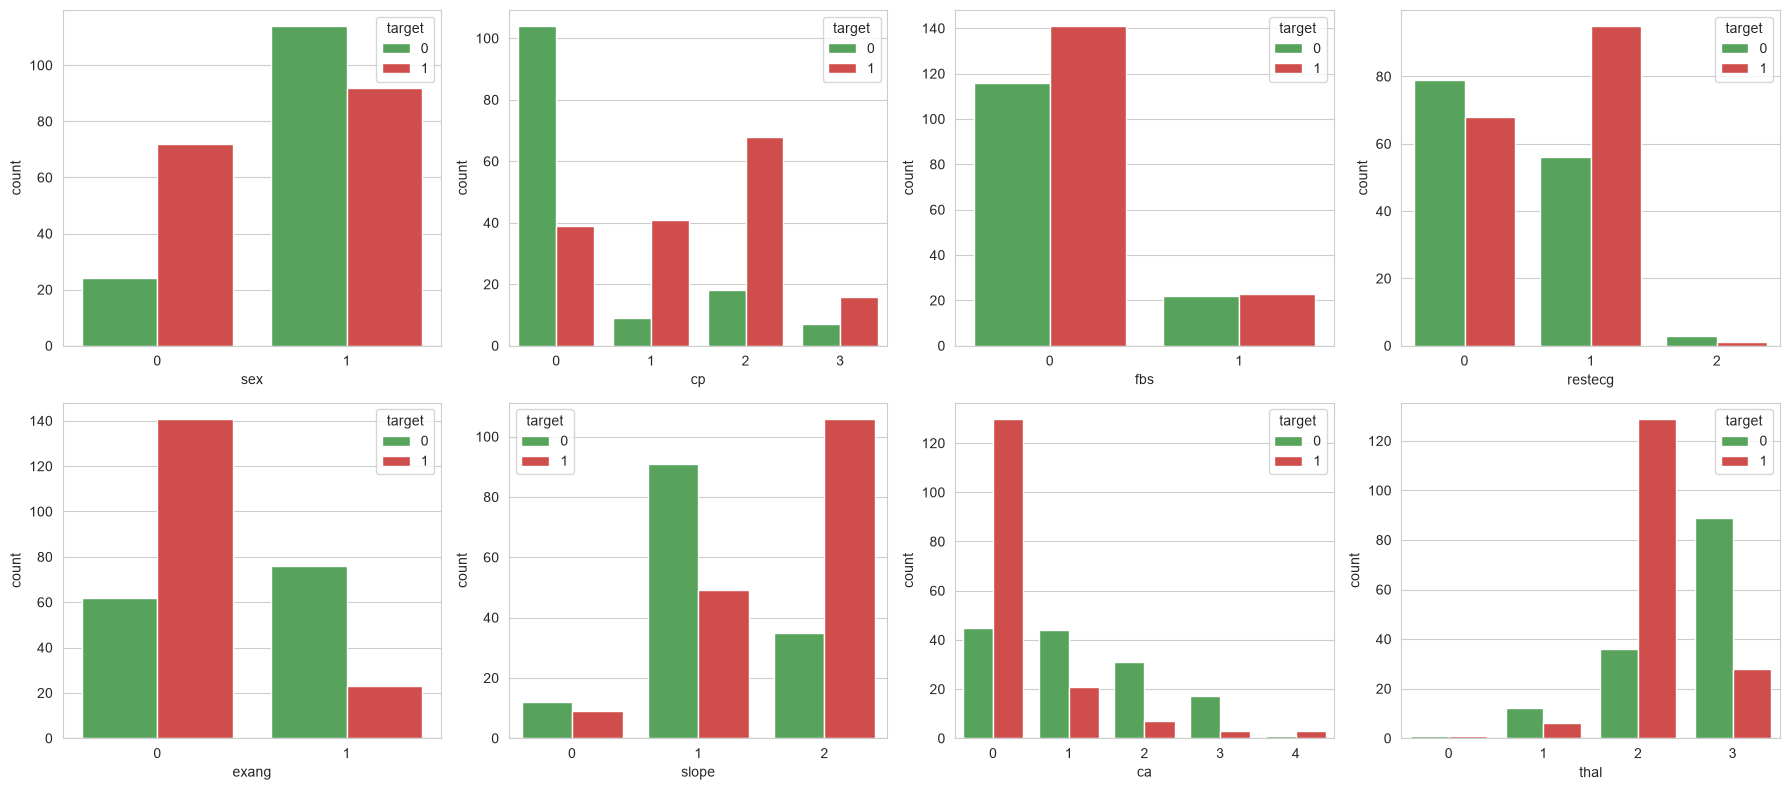

In [5]:
fig, ax = plt.subplots(2,4, figsize=(18,8))
for a, c in zip(ax.ravel(), categorical_cols):
    sns.countplot(data=df, x=c, hue='target', ax=a, palette=['#4CAF50','#E53935'])
plt.tight_layout(); plt.show()

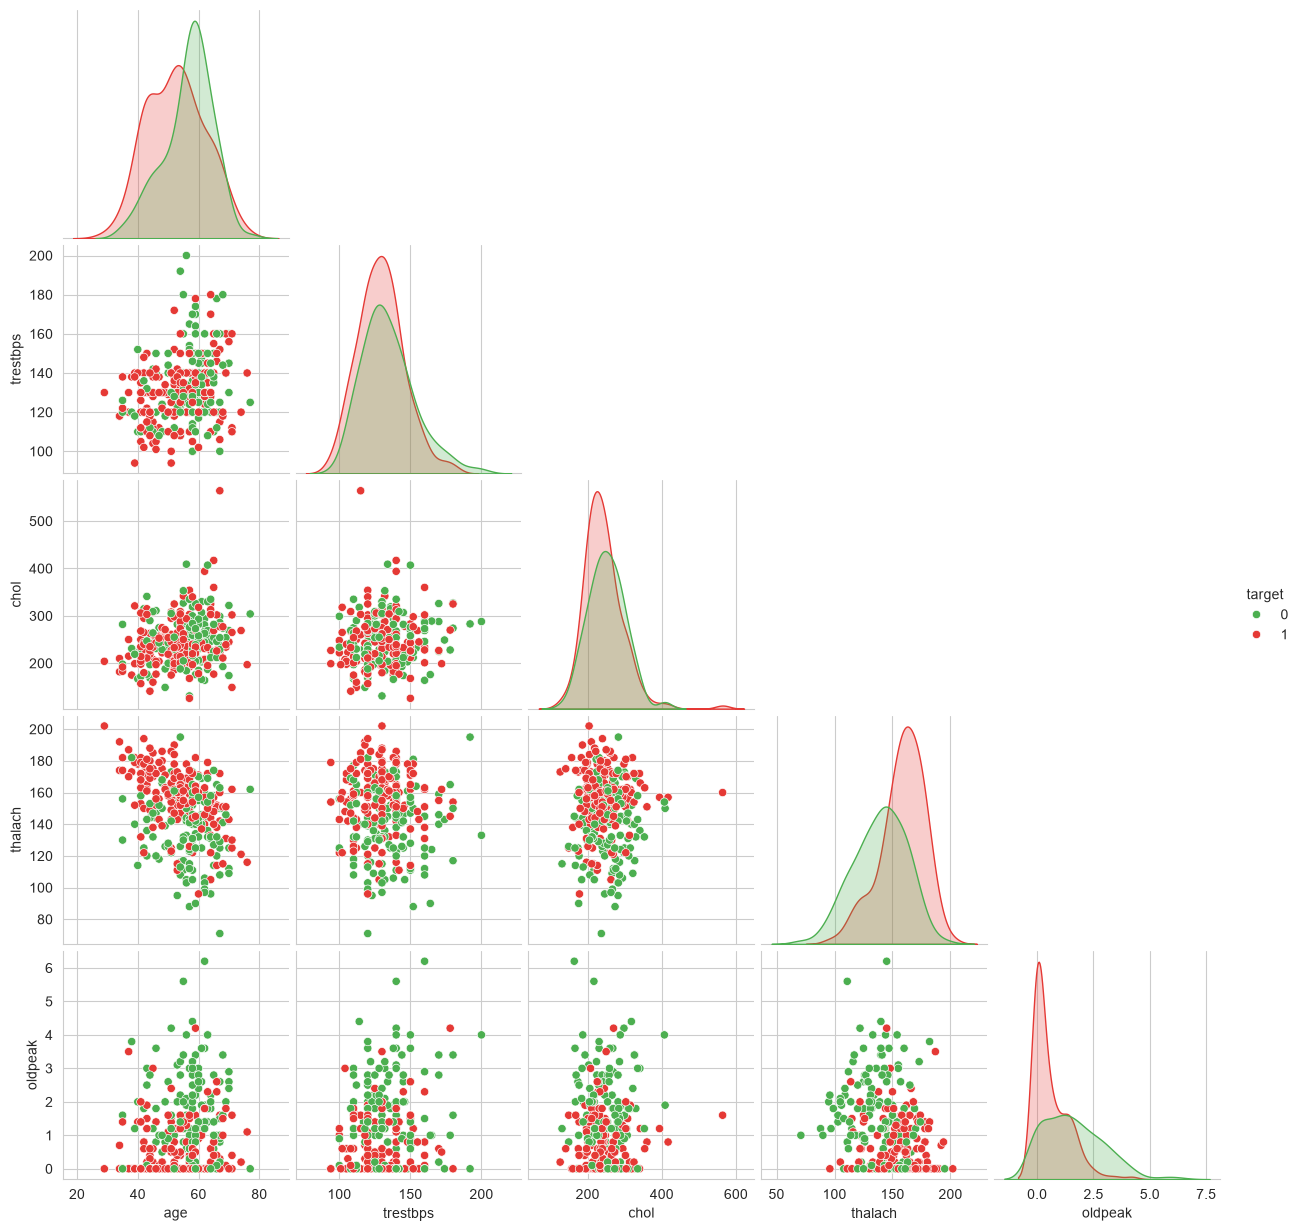

In [6]:
sns.pairplot(df[['age','trestbps','chol','thalach','oldpeak','target']], hue='target', palette=['#4CAF50','#E53935'], corner=True); plt.show()

## Task 4: Data Splitting and Cross-Validation Setup

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

(241, 13) (61, 13)


**Cross-validation kyun?** Training data ko 5 hisson (folds) mein baanta jata hai; har baar 4 folds par train aur 1 par validate hota hai. Is tarah model ko sirf ek lucky split par nahi parkha jata, performance ka zyada reliable andaza milta hai, aur hyperparameters aise chune jate hain jo naye data par bhi chalein. Isse overfitting pakadna aur kam karna aasan hota hai. Test set ko aakhir tak touch nahi kiya jata.

## Task 5: Model Implementation, Cross-Validation and Hyperparameter Tuning

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

configs = {
 'KNN': (KNeighborsClassifier(), {'clf__n_neighbors':[3,5,7,9,11,15], 'clf__weights':['uniform','distance'], 'clf__p':[1,2]}),
 'Logistic Regression': (LogisticRegression(max_iter=2000), {'clf__C':[0.01,0.1,1,10,100], 'clf__penalty':['l2']}),
 'Decision Tree': (DecisionTreeClassifier(random_state=42), {'clf__max_depth':[2,3,4,5,7,None], 'clf__min_samples_split':[2,5,10], 'clf__min_samples_leaf':[1,3,5]}),
 'Random Forest': (RandomForestClassifier(random_state=42), {'clf__n_estimators':[100,200,300], 'clf__max_depth':[3,5,8,None], 'clf__min_samples_leaf':[1,3,5]}),
 'SVM': (SVC(probability=True, random_state=42), {'clf__C':[0.1,1,10], 'clf__kernel':['linear','rbf'], 'clf__gamma':['scale',0.01,0.1]}),
}
best_models, cv_scores = {}, {}
for name, (clf, grid) in configs.items():
    pipe = Pipeline([('prep', preprocess), ('clf', clf)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)
    best_models[name] = gs.best_estimator_; cv_scores[name] = gs.best_score_
    print(f'{name:20s} CV AUC={gs.best_score_:.4f}  best params={gs.best_params_}')

KNN                  CV AUC=0.9156  best params={'clf__n_neighbors': 11, 'clf__p': 1, 'clf__weights': 'distance'}
Logistic Regression  CV AUC=0.9278  best params={'clf__C': 1, 'clf__penalty': 'l2'}
Decision Tree        CV AUC=0.8512  best params={'clf__max_depth': 7, 'clf__min_samples_leaf': 5, 'clf__min_samples_split': 2}
Random Forest        CV AUC=0.9169  best params={'clf__max_depth': 3, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 300}
SVM                  CV AUC=0.9219  best params={'clf__C': 10, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}


Har algorithm ke liye 5.1 KNN, 5.2 Logistic Regression, 5.3 Decision Tree, 5.4 Random Forest, 5.5 SVM ek hi loop mein `GridSearchCV` (5-fold CV) ke saath train aur tune hue hain.

## Task 6: Model Evaluation

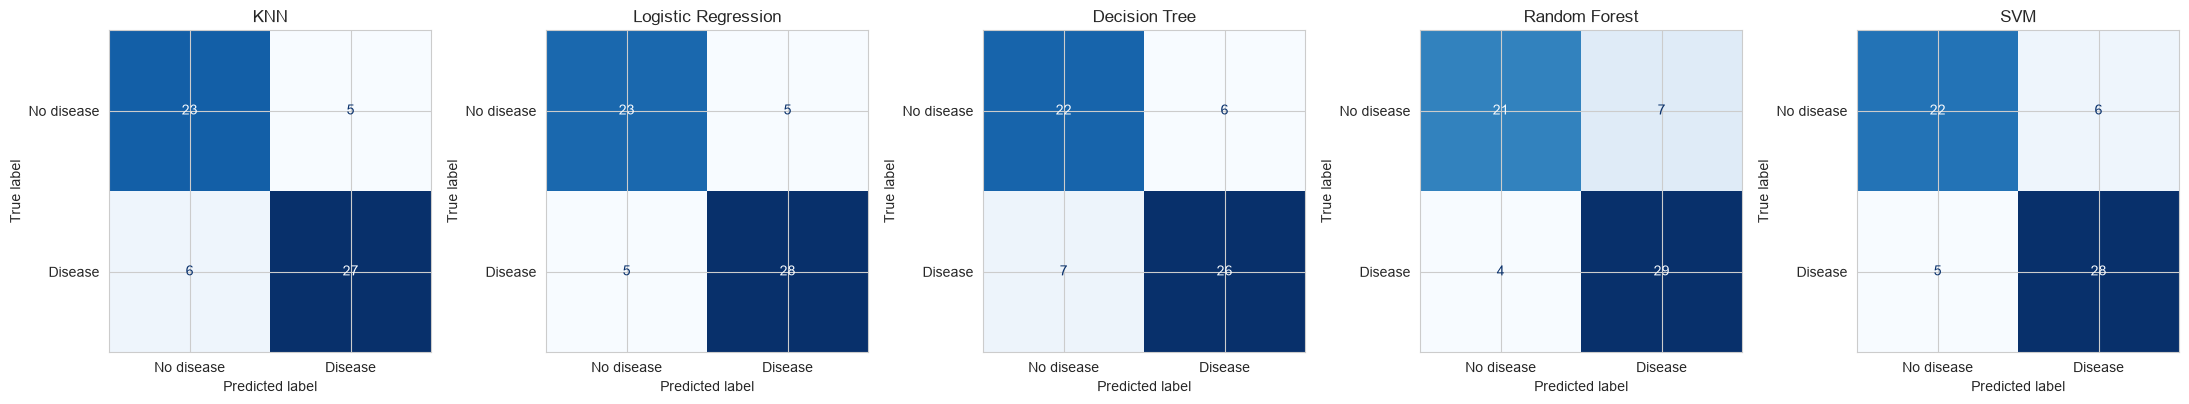

,CV_AUC,Accuracy,Precision,Recall,F1,AUC
Model,,,,,,
KNN,0.9156,0.8197,0.8438,0.8182,0.8308,0.9026
Logistic Regression,0.9278,0.8361,0.8485,0.8485,0.8485,0.9048
Decision Tree,0.8512,0.7869,0.8125,0.7879,0.8000,0.8301
Random Forest,0.9169,0.8197,0.8056,0.8788,0.8406,0.8918
SVM,0.9219,0.8197,0.8235,0.8485,0.8358,0.8950


In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
rows = []
fig, ax = plt.subplots(1,5, figsize=(22,4))
for a, (name, m) in zip(ax, best_models.items()):
    p = m.predict(X_test); pr = m.predict_proba(X_test)[:,1]
    rows.append(dict(Model=name, CV_AUC=cv_scores[name], Accuracy=accuracy_score(y_test,p), Precision=precision_score(y_test,p),
                     Recall=recall_score(y_test,p), F1=f1_score(y_test,p), AUC=roc_auc_score(y_test,pr)))
    ConfusionMatrixDisplay(confusion_matrix(y_test,p), display_labels=['No disease','Disease']).plot(ax=a, colorbar=False, cmap='Blues'); a.set_title(name)
plt.tight_layout(); plt.show()
results = pd.DataFrame(rows).set_index('Model').round(4)
display(results)

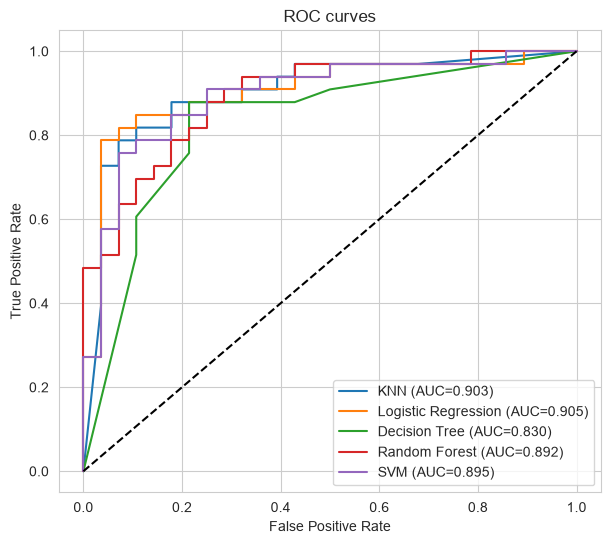

In [10]:
plt.figure(figsize=(7,6))
for name, m in best_models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:,1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={results.loc[name,'AUC']:.3f})")
plt.plot([0,1],[0,1],'k--'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC curves'); plt.legend(); plt.show()

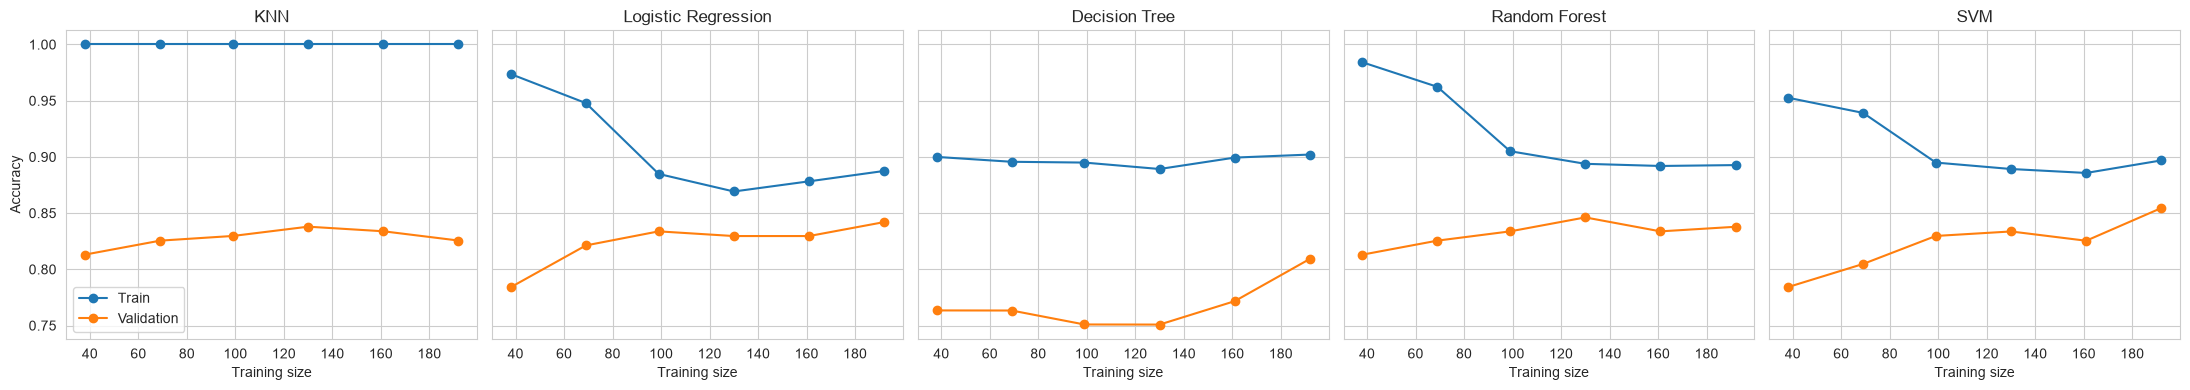

In [11]:
from sklearn.model_selection import learning_curve
fig, ax = plt.subplots(1,5, figsize=(22,4), sharey=True)
for a, (name, m) in zip(ax, best_models.items()):
    sz, tr, va = learning_curve(m, X_train, y_train, cv=cv, scoring='accuracy', train_sizes=np.linspace(0.2,1,6), n_jobs=-1)
    a.plot(sz, tr.mean(1), 'o-', label='Train'); a.plot(sz, va.mean(1), 'o-', label='Validation'); a.set_title(name); a.set_xlabel('Training size')
ax[0].set_ylabel('Accuracy'); ax[0].legend(); plt.tight_layout(); plt.show()

**Bias-variance:** Jahan train score bohot zyada aur validation score us se kaafi neeche ho (gap bada) wahan **high variance / overfitting** hai (aam taur par Decision Tree aur Random Forest). Jahan dono curves neeche aur paas paas hon wahan **high bias / underfitting** hai. Jin models mein gap chhota aur validation score acha ho (aksar Logistic Regression / SVM) wo behtar balance rakhte hain.

## Task 7: Comprehensive Model Comparison

,CV_AUC,Accuracy,Precision,Recall,F1,AUC
Model,,,,,,
Logistic Regression,0.9278,0.8361,0.8485,0.8485,0.8485,0.9048
KNN,0.9156,0.8197,0.8438,0.8182,0.8308,0.9026
SVM,0.9219,0.8197,0.8235,0.8485,0.8358,0.8950
Random Forest,0.9169,0.8197,0.8056,0.8788,0.8406,0.8918
Decision Tree,0.8512,0.7869,0.8125,0.7879,0.8000,0.8301


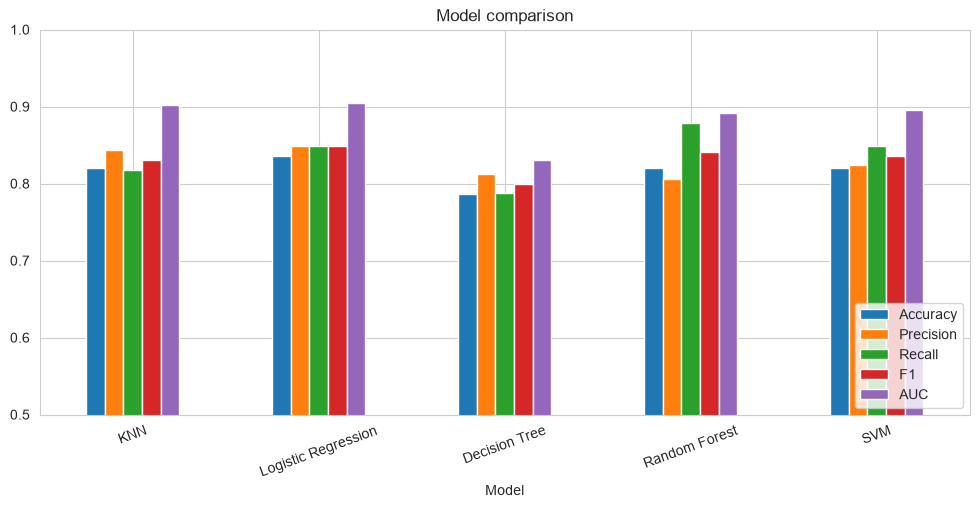

In [12]:
display(results.sort_values('AUC', ascending=False))
results[['Accuracy','Precision','Recall','F1','AUC']].plot(kind='bar', figsize=(12,5), rot=20); plt.ylim(0.5,1); plt.title('Model comparison'); plt.legend(loc='lower right'); plt.show()

In [13]:
# Best model: CV AUC (zyada stable) + Recall (bimari miss na ho) + F1 ko mila kar score
score = results['CV_AUC']*0.4 + results['Recall']*0.3 + results['F1']*0.3
best_name = score.idxmax()
print('Best model:', best_name); print(score.round(4).sort_values(ascending=False))

Best model: Random Forest
Model
Random Forest          0.8826
Logistic Regression    0.8802
SVM                    0.8740
KNN                    0.8609
Decision Tree          0.8168
dtype: float64


**Trade-offs:** Medical problem mein **Recall** sabse ahem hai, kyunke bimar mareez ko "healthy" keh dena (False Negative) khatarnak hai. Precision kam ho to sirf extra tests hote hain. Accuracy akeli kaafi nahi, F1 dono ka balance deta hai aur AUC threshold-independent ranking quality batata hai. Isliye best model in sab ko mila kar chuna gaya hai.

## Save the best model (pickle)

In [16]:
best_name = 'Logistic Regression'
final = best_models[best_name].fit(X, y)
joblib.dump({'model': final, 'features': list(X.columns), 'name': best_name}, 'heart_model.pkl')
print('Saved heart_model.pkl ->', best_name)

Saved heart_model.pkl -> Logistic Regression


## Important data note (target meaning)
Correlations dikhate hain ke `target=1` wale patients mein `exang`, `oldpeak`, `ca` kam aur `thalach` zyada hota hai (`corr` = -0.44, -0.43, -0.41, +0.42). Yeh healthy patients ki alamat hai, yaani is file mein `target=1` practically **"disease nahi"** ke barabar behave karta hai, jabke description ulta kehti hai. Model ki metrics (accuracy, AUC...) is se mutassir nahi hoti, lekin website par result dikhate waqt label ulta kar diya gaya hai (`disease probability = 1 - P(target=1)`). Dataset ke source se confirm kar lena behtar hai.